# Lab 07: Statistical Analysis of Housing Dataset

## Cell 1: Import libraries and load the dataset

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the existing dataset
df = pd.read_csv('Housing.csv')

# Display the first five rows
print("FIRST FIVE ROWS OF THE DATASET:")
display(df.head())

# Display dataset information
print("\nDATASET INFORMATION:")
df.info()

# Display dataset shape
print("\nDATASET SHAPE:", df.shape)

FIRST FIVE ROWS OF THE DATASET:


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished



DATASET INFORMATION:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB

DATASET SHAPE: (545, 13)


## Cell 2: Calculate mean, median, mode, and standard deviation

In [37]:
# Select numerical columns
numeric_df = df.select_dtypes(include=np.number)

# Calculate mean
mean_values = numeric_df.mean()

# Calculate median
median_values = numeric_df.median()

# Calculate mode for all columns
mode_values = df.mode().iloc[0]

# Calculate standard deviation
std_values = numeric_df.std()

# Display results
print("MEAN:")
print(mean_values)

print("\nMEDIAN:")
print(median_values)

print("\nMODE:")
print(mode_values)

print("\nSTANDARD DEVIATION:")
print(std_values)

MEAN:
price        4.766729e+06
area         5.150541e+03
bedrooms     2.965138e+00
bathrooms    1.286239e+00
stories      1.805505e+00
parking      6.935780e-01
dtype: float64

MEDIAN:
price        4340000.0
area            4600.0
bedrooms           3.0
bathrooms          1.0
stories            2.0
parking            0.0
dtype: float64

MODE:
price                      3500000
area                        6000.0
bedrooms                       3.0
bathrooms                      1.0
stories                        2.0
mainroad                       yes
guestroom                       no
basement                        no
hotwaterheating                 no
airconditioning                 no
parking                        0.0
prefarea                        no
furnishingstatus    semi-furnished
Name: 0, dtype: object

STANDARD DEVIATION:
price        1.870440e+06
area         2.170141e+03
bedrooms     7.380639e-01
bathrooms    5.024696e-01
stories      8.674925e-01
parking      8.615858e-01

## Cell 3: Calculate and display the correlation matrix

In [38]:
# Convert categorical columns into numerical dummy variables
encoded_df = pd.get_dummies(df, drop_first=True, dtype=int)

# Calculate correlation matrix
correlation_matrix = encoded_df.corr()

# Display correlation matrix
print("CORRELATION MATRIX:")
display(correlation_matrix.round(2))

CORRELATION MATRIX:


,price,area,bedrooms,bathrooms,stories,parking,mainroad_yes,guestroom_yes,basement_yes,hotwaterheating_yes,airconditioning_yes,prefarea_yes,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
price,1.00,0.54,0.37,0.52,0.42,0.38,0.30,0.26,0.19,0.09,0.45,0.33,0.06,-0.28
area,0.54,1.00,0.15,0.19,0.08,0.35,0.29,0.14,0.05,-0.01,0.22,0.23,0.01,-0.14
bedrooms,0.37,0.15,1.00,0.37,0.41,0.14,-0.01,0.08,0.10,0.05,0.16,0.08,0.05,-0.13
bathrooms,0.52,0.19,0.37,1.00,0.33,0.18,0.04,0.13,0.10,0.07,0.19,0.06,0.03,-0.13
stories,0.42,0.08,0.41,0.33,1.00,0.05,0.12,0.04,-0.17,0.02,0.29,0.04,-0.00,-0.08
parking,0.38,0.35,0.14,0.18,0.05,1.00,0.20,0.04,0.05,0.07,0.16,0.09,0.04,-0.17
mainroad_yes,0.30,0.29,-0.01,0.04,0.12,0.20,1.00,0.09,0.04,-0.01,0.11,0.20,0.01,-0.13
guestroom_yes,0.26,0.14,0.08,0.13,0.04,0.04,0.09,1.00,0.37,-0.01,0.14,0.16,0.01,-0.10
basement_yes,0.19,0.05,0.10,0.10,-0.17,0.05,0.04,0.37,1.00,0.00,0.05,0.23,0.05,-0.12
hotwaterheating_yes,0.09,-0.01,0.05,0.07,0.02,0.07,-0.01,-0.01,0.00,1.00,-0.13,-0.06,0.06,-0.06


## Cell 4: Plot the correlation matrix

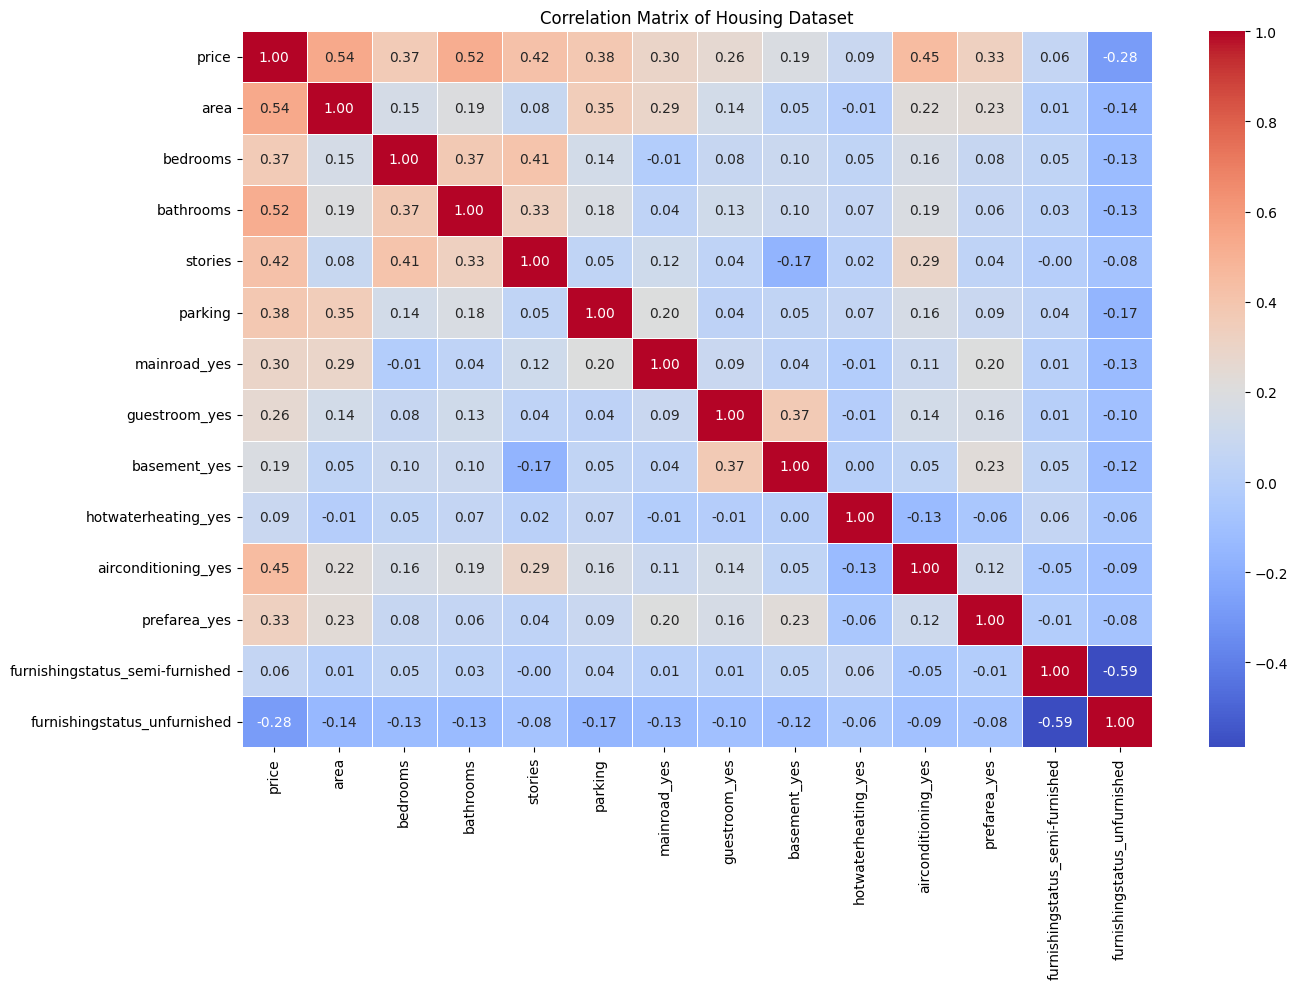

In [39]:
# Plot correlation heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Matrix of Housing Dataset")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Cell 5: Calculate and display the covariance matrix

In [40]:
# Calculate covariance matrix
covariance_matrix = encoded_df.cov()

# Display covariance matrix
print("COVARIANCE MATRIX:")
display(covariance_matrix.round(2))

COVARIANCE MATRIX:


,price,area,bedrooms,bathrooms,stories,parking,mainroad_yes,guestroom_yes,basement_yes,hotwaterheating_yes,airconditioning_yes,prefarea_yes,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
price,3.498544e+12,2.175676e+09,505946.43,486409.33,682644.63,619467.32,193607.54,182974.75,167084.95,36453.62,394111.23,261721.52,58750.85,-246352.58
area,2.175676e+09,4.709512e+06,243.23,211.35,158.13,659.99,218.56,116.56,49.14,-4.19,224.51,216.18,6.59,-144.93
bedrooms,5.059464e+05,2.432300e+02,0.54,0.14,0.26,0.09,-0.00,0.02,0.03,0.01,0.06,0.02,0.02,-0.04
bathrooms,4.864093e+05,2.113500e+02,0.14,0.25,0.14,0.08,0.01,0.02,0.02,0.01,0.04,0.01,0.01,-0.03
stories,6.826446e+05,1.581300e+02,0.26,0.14,0.75,0.03,0.04,0.01,-0.07,0.00,0.12,0.02,-0.00,-0.03
parking,6.194673e+05,6.599900e+02,0.09,0.08,0.03,0.74,0.06,0.01,0.02,0.01,0.06,0.03,0.02,-0.07
mainroad_yes,1.936075e+05,2.185600e+02,-0.00,0.01,0.04,0.06,0.12,0.01,0.01,-0.00,0.02,0.03,0.00,-0.02
guestroom_yes,1.829748e+05,1.165600e+02,0.02,0.02,0.01,0.01,0.01,0.15,0.07,-0.00,0.02,0.03,0.00,-0.02
basement_yes,1.670850e+05,4.914000e+01,0.03,0.02,-0.07,0.02,0.01,0.07,0.23,0.00,0.01,0.05,0.01,-0.03
hotwaterheating_yes,3.645362e+04,-4.190000e+00,0.01,0.01,0.00,0.01,-0.00,-0.00,0.00,0.04,-0.01,-0.01,0.01,-0.01


## Cell 6: Plot the covariance matrix

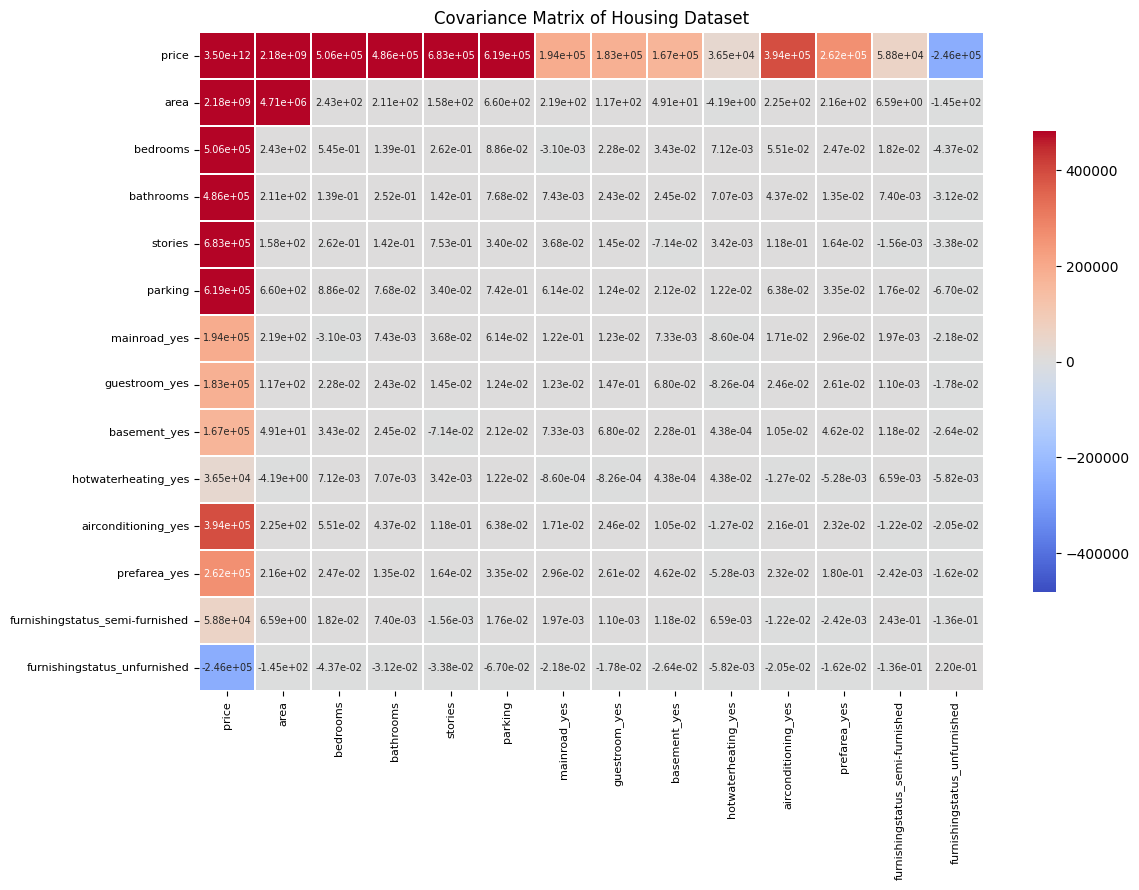

In [43]:
# Plot covariance heatmap
plt.figure(figsize=(12, 9))

off_diagonal = covariance_matrix.values[
    ~np.eye(covariance_matrix.shape[0], dtype=bool)
]

limit = np.percentile(np.abs(off_diagonal), 95)

sns.heatmap(
    covariance_matrix,
    cmap='coolwarm',
    center=0,
    vmin=-limit,
    vmax=limit,
    annot=True,
    fmt='.2e',
    annot_kws={"size": 7},
    linewidths=0.3,
    cbar_kws={"shrink": 0.7}
)

plt.title("Covariance Matrix of Housing Dataset", fontsize=12)
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.show()

## Cell 7: Conclusion

In [42]:
print("CONCLUSION")
print("-" * 40)

print("1. Mean, median, mode and standard deviation were calculated.")
print("2. Numerical and categorical columns were analyzed.")
print("3. The correlation matrix was calculated and visualized.")
print("4. The covariance matrix was calculated and visualized.")
print("5. Heatmaps were used to visualize relationships between variables.")

CONCLUSION
----------------------------------------
1. Mean, median, mode and standard deviation were calculated.
2. Numerical and categorical columns were analyzed.
3. The correlation matrix was calculated and visualized.
4. The covariance matrix was calculated and visualized.
5. Heatmaps were used to visualize relationships between variables.
